# 这个notebook展示如何使用Keras_nlp包来使用大型语言模型

In [1]:
import numpy as np
import re
import keras_nlp
import keras

In [2]:
def readFasta(inpFile):
    _seq = []
    _id = []
    for line in open(inpFile):
        if line.startswith('>'):
           _id.append(line.replace('>','').split()[0])
        else:
           _seq.append(line.replace('\n',''))
    return _seq, _id

In [3]:
[posTrain_seq,posTrain_id] = readFasta('C:/Users/dell/Desktop/autobioseqpy2.0_20200805/examples/T3T4/dataset/trainT3.txt')
posTrain_Label = np.ones(len(posTrain_id))

[negTrain_seq,negTrain_id] = readFasta('C:/Users/dell/Desktop/autobioseqpy2.0_20200805/examples/T3T4/dataset/trainT4.txt')
negTrain_Label = np.zeros(len(negTrain_id))

[posTest_seq,posTest_id] = readFasta('C:/Users/dell/Desktop/autobioseqpy2.0_20200805/examples/T3T4/dataset/testT3.txt')
posTest_Label = np.ones(len(posTest_id))

[negTest_seq,negTest_id] = readFasta('C:/Users/dell/Desktop/autobioseqpy2.0_20200805/examples/T3T4/dataset/testT4.txt')
negTest_Label = np.zeros(len(negTest_id))


In [4]:
Train_seq = np.hstack((posTrain_seq, negTrain_seq))
Train_Label = np.hstack((posTrain_Label,negTrain_Label))

Test_seq = np.hstack((posTest_seq, negTest_seq))
Test_Label = np.hstack((posTest_Label,negTest_Label))

In [5]:
Train_seq_split = []
for i in range(Train_seq.shape[0]):
    text_list = re.findall(".{1}",Train_seq[i])
    new_text = " ".join(text_list)
    Train_seq_split = np.append(Train_seq_split,new_text)

Test_seq_split = []
for i in range(Test_seq.shape[0]):
    text_list = re.findall(".{1}",Test_seq[i])
    new_text = " ".join(text_list)
    Test_seq_split = np.append(Test_seq_split,new_text)


In [6]:
Train_seq_split

array(['M R K A M R R V D Q P R L Q G T P V G V R E Q S A S N A D A P A R N E P A A Q P A P E R P A G M L R G L A R Y L P R Y R S V R P P A T P A S A Q T S S R P T T S A R P V H H G G S G S S V R M N E A P A D P S Q T P Q L P Q F S N I E R A R F H S V A T D S H H L G P T R P T V P P T V G A S L Q R S T P I P P Y R N V L S Q W Q Q H Y D A D R N G W H S A W H Q A N S D T S V V E T S T G Q A L K A T A D M L E N A T L A E R V S L E L R S V P L P Q F P E Q T F R L S H L R H I T I D A A G L M K L P A D M Q K F A A L E T L T L A R N P L R S L P A S I S S L R R L R E L S I L A C P T L K E L P E S L A G T N A S G E H E G L V N L Q R L Q L E E T G I T S L P A S I A S L Q N L K R L Q V R N S P L S A V A P A I H Q M P K L E E L D F Q G C T A L R N Y P P I F G G S A P L K R L N L K D C S N L R T L P L D I H N L T Q L E E L D L R G C D N L S R L P S S I G R L P A N C I I L V P P H L Q V Q L D Q R R L S A R Q A E P Q R T D P S I P G P S G H G S S A S S V T T T E L L H K A A L E R I E D A A H A M L S 

In [7]:
classifier = keras_nlp.models.BertClassifier.from_preset('bert_tiny_en_uncased',num_classes=2,activation='softmax')

In [8]:
classifier.evaluate(x=Test_seq_split,y=Test_Label)

7/7 [==============================] - 13s 529ms/step - loss: 0.6967 - sparse_categorical_accuracy: 0.3744


[0.6967433094978333, 0.37438422441482544]

In [9]:
classifier = keras_nlp.models.BertClassifier.from_preset(
    'bert_tiny_en_uncased',
    num_classes=2,
    activation='softmax',
)


In [10]:
classifier.fit(x=Train_seq_split, y=Train_Label, epochs=50)

Epoch 1/50
15/15 [==============================] - 38s 2s/step - loss: 0.7902 - sparse_categorical_accuracy: 0.3397
Epoch 2/50
15/15 [==============================] - 4s 267ms/step - loss: 0.7142 - sparse_categorical_accuracy: 0.4473
Epoch 3/50
15/15 [==============================] - 4s 266ms/step - loss: 0.6973 - sparse_categorical_accuracy: 0.4810
Epoch 4/50
15/15 [==============================] - 4s 268ms/step - loss: 0.6966 - sparse_categorical_accuracy: 0.4684
Epoch 5/50
15/15 [==============================] - 4s 269ms/step - loss: 0.6929 - sparse_categorical_accuracy: 0.4979
Epoch 6/50
15/15 [==============================] - 4s 270ms/step - loss: 0.6971 - sparse_categorical_accuracy: 0.5274
Epoch 7/50
15/15 [==============================] - 4s 271ms/step - loss: 0.6915 - sparse_categorical_accuracy: 0.5338
Epoch 8/50
15/15 [==============================] - 4s 271ms/step - loss: 0.6901 - sparse_categorical_accuracy: 0.5654
Epoch 9/50
15/15 [==============================] 

In [11]:
classifier.evaluate(x=Test_seq_split,y=Test_Label)

7/7 [==============================] - 3s 137ms/step - loss: 0.5841 - sparse_categorical_accuracy: 0.7635


[0.5840628743171692, 0.7635467648506165]

In [12]:
probability=classifier.predict(x=Test_seq_split)

7/7 [==============================] - 3s 190ms/step


In [13]:
probability

array([[0.8785515 , 0.12144857],
       [0.08466443, 0.91533554],
       [0.88659024, 0.11340976],
       [0.5874888 , 0.4125112 ],
       [0.0845526 , 0.9154474 ],
       [0.09160732, 0.9083927 ],
       [0.10772818, 0.8922718 ],
       [0.8913525 , 0.10864758],
       [0.09129997, 0.90870005],
       [0.08870542, 0.9112946 ],
       [0.08309313, 0.9169069 ],
       [0.08452739, 0.91547257],
       [0.08334089, 0.9166591 ],
       [0.16571605, 0.83428395],
       [0.08392601, 0.91607404],
       [0.0843955 , 0.9156045 ],
       [0.08364997, 0.91635   ],
       [0.09666672, 0.9033333 ],
       [0.89713097, 0.10286898],
       [0.08605008, 0.9139499 ],
       [0.08811259, 0.9118874 ],
       [0.08445289, 0.91554713],
       [0.08437292, 0.91562706],
       [0.08454356, 0.9154564 ],
       [0.08458816, 0.91541183],
       [0.11661345, 0.88338655],
       [0.08340129, 0.91659874],
       [0.08512253, 0.91487753],
       [0.08385632, 0.91614366],
       [0.08468624, 0.9153137 ],
       [0.

In [14]:
prediction_class=np.around(probability[:,1])

In [15]:
prediction_class

array([0., 1., 0., 0., 1., 1., 1., 0., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 0., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       0., 1., 1., 1., 0., 1., 1., 1., 1., 0., 1., 1., 1., 0., 1., 0., 1.,
       0., 1., 1., 0., 0., 0., 1., 0., 1., 1., 1., 1., 1., 1., 1., 1., 0.,
       1., 0., 1., 0., 1., 1., 0., 1., 1., 0., 0., 1., 1., 0., 1., 0., 0.,
       1., 1., 1., 1., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0.,
       1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       1., 1., 0., 1., 0., 0., 1., 0., 1., 1., 1., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 1., 1., 0., 0., 0., 1., 1., 0., 1., 0.,
       1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 1.,
       0., 0., 0., 1., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0.,
       0., 0., 1., 0., 0., 0., 0., 0., 1., 0., 0., 0., 1., 0., 0., 0.],
      dtype=float32)

In [20]:
import analysisPlot

In [21]:
from sklearn.metrics import accuracy_score,f1_score,roc_auc_score,recall_score,precision_score,confusion_matrix,matthews_corrcoef,auc,roc_curve

In [22]:
cm=confusion_matrix(Test_Label,prediction_class)
print(cm)
print("ACC: %f "%accuracy_score(Test_Label,prediction_class))
print("F1: %f "%f1_score(Test_Label,prediction_class))
print("Recall: %f "%recall_score(Test_Label,prediction_class))
print("Pre: %f "%precision_score(Test_Label,prediction_class))
print("MCC: %f "%matthews_corrcoef(Test_Label,prediction_class))
fpr,tpr,threshold = roc_curve(Test_Label, probability[:,1])
auc_roc = auc(fpr,tpr)
print("AUC: %f "%auc_roc)

[[89 23]
 [25 66]]
ACC: 0.763547 
F1: 0.733333 
Recall: 0.725275 
Pre: 0.741573 
MCC: 0.521095 
AUC: 0.828738 


<Figure size 640x480 with 0 Axes>

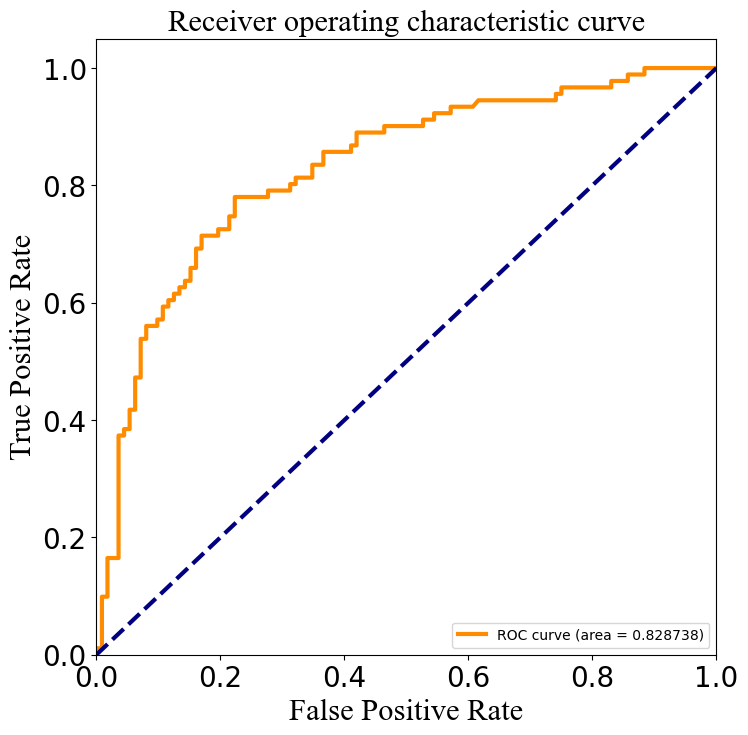

In [23]:
analysisPlot.plotROC(Test_Label, probability[:,1],showFig=True,savePath=None)

In [24]:
vocab = ["[UNK]", "[CLS]", "[SEP]", "[PAD]", "[MASK]"]
vocab += ["G","A","V","L","I","P","F","Y","W","S","T","C","M","N","Q","D","E","K","R","H","X","B","J","O","U","Z"]

In [25]:
BATCH_SIZE = 16
EPOCHS = 50
MAX_SEQUENCE_LENGTH = 512
VOCAB_SIZE = 20

EMBED_DIM = 128
INTERMEDIATE_DIM = 256

In [26]:
tokenizer = keras_nlp.tokenizers.WordPieceTokenizer(
    vocabulary=vocab,
    lowercase=False,
    sequence_length=MAX_SEQUENCE_LENGTH,
)

In [27]:
input_train = tokenizer(Train_seq_split)
input_test = tokenizer(Test_seq_split)

In [28]:
input_ids = keras.Input(shape=(None,), dtype="int64", name="input_ids")

x = keras_nlp.layers.TokenAndPositionEmbedding(
    vocabulary_size=VOCAB_SIZE,
    sequence_length=MAX_SEQUENCE_LENGTH,
    embedding_dim=EMBED_DIM,
    mask_zero=True,
)(input_ids)

x = keras_nlp.layers.FNetEncoder(intermediate_dim=INTERMEDIATE_DIM)(inputs=x)
x = keras_nlp.layers.FNetEncoder(intermediate_dim=INTERMEDIATE_DIM)(inputs=x)
x = keras_nlp.layers.FNetEncoder(intermediate_dim=INTERMEDIATE_DIM)(inputs=x)


x = keras.layers.GlobalAveragePooling1D()(x)
x = keras.layers.Dropout(0.1)(x)
outputs = keras.layers.Dense(1, activation="sigmoid")(x)

fnet_classifier = keras.Model(input_ids, outputs, name="fnet_classifier")

In [29]:
fnet_classifier.summary()
fnet_classifier.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
fnet_classifier.fit(x=input_train, y=Train_Label, epochs=EPOCHS)

Model: "fnet_classifier"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_ids (InputLayer)      [(None, None)]            0         
                                                                 
 token_and_position_embeddin  (None, None, 128)        68096     
 g (TokenAndPositionEmbeddin                                     
 g)                                                              
                                                                 
 f_net_encoder (FNetEncoder)  (None, None, 128)        66432     
                                                                 
 f_net_encoder_1 (FNetEncode  (None, None, 128)        66432     
 r)                                                              
                                                                 
 f_net_encoder_2 (FNetEncode  (None, None, 128)        66432     
 r)                                                

In [30]:
fnet_classifier.evaluate(x=input_test,y=Test_Label, batch_size=BATCH_SIZE)

13/13 [==============================] - 0s 15ms/step - loss: 0.6275 - accuracy: 0.7882


[0.6274768114089966, 0.7881773114204407]

In [31]:
tokenizer = keras_nlp.models.BertTokenizer(
    vocabulary=vocab,
)

preprocessor = keras_nlp.models.BertPreprocessor(
    tokenizer=tokenizer,
    sequence_length=512,
)

backbone = keras_nlp.models.BertBackbone(
    vocabulary_size=20,
    num_layers=2,
    num_heads=2,
    hidden_dim=256,
    intermediate_dim=64,
    max_sequence_length=512,
)

classifier = keras_nlp.models.BertClassifier(
    backbone=backbone,
    preprocessor=preprocessor,
    num_classes=2,
    activation='softmax'
)

classifier.fit(x=Train_seq_split, y=Train_Label, epochs=30)

Epoch 1/30
15/15 [==============================] - 47s 2s/step - loss: 0.8096 - sparse_categorical_accuracy: 0.4451
Epoch 2/30
15/15 [==============================] - 5s 310ms/step - loss: 0.7092 - sparse_categorical_accuracy: 0.4451
Epoch 3/30
15/15 [==============================] - 5s 322ms/step - loss: 0.6894 - sparse_categorical_accuracy: 0.5000
Epoch 4/30
15/15 [==============================] - 5s 313ms/step - loss: 0.6881 - sparse_categorical_accuracy: 0.5464
Epoch 5/30
15/15 [==============================] - 5s 313ms/step - loss: 0.6946 - sparse_categorical_accuracy: 0.5549
Epoch 6/30
15/15 [==============================] - 5s 313ms/step - loss: 0.7001 - sparse_categorical_accuracy: 0.5549
Epoch 7/30
15/15 [==============================] - 5s 325ms/step - loss: 0.6984 - sparse_categorical_accuracy: 0.5549
Epoch 8/30
15/15 [==============================] - 5s 339ms/step - loss: 0.7019 - sparse_categorical_accuracy: 0.5549
Epoch 9/30
15/15 [==============================] 

In [32]:
classifier.evaluate(x=Test_seq_split,y=Test_Label)

7/7 [==============================] - 5s 572ms/step - loss: 0.7839 - sparse_categorical_accuracy: 0.6355


[0.7839254140853882, 0.6354679465293884]

In [33]:
tokenizer = keras_nlp.models.BertTokenizer.from_preset(
    'bert_tiny_en_uncased',
)

tokenizer(Train_seq_split)

<tf.RaggedTensor [[1049, 1054, 1047, 1037, 1049, 1054, 1054, 1058, 1040, 1053, 1052, 1054,
  1048, 1053, 1043, 1056, 1052, 1058, 1043, 1058, 1054, 1041, 1053, 1055,
  1037, 1055, 1050, 1037, 1040, 1037, 1052, 1037, 1054, 1050, 1041, 1052,
  1037, 1037, 1053, 1052, 1037, 1052, 1041, 1054, 1052, 1037, 1043, 1049,
  1048, 1054, 1043, 1048, 1037, 1054, 1061, 1048, 1052, 1054, 1061, 1054,
  1055, 1058, 1054, 1052, 1052, 1037, 1056, 1052, 1037, 1055, 1037, 1053,
  1056, 1055, 1055, 1054, 1052, 1056, 1056, 1055, 1037, 1054, 1052, 1058,
  1044, 1044, 1043, 1043, 1055, 1043, 1055, 1055, 1058, 1054, 1049, 1050,
  1041, 1037, 1052, 1037, 1040, 1052, 1055, 1053, 1056, 1052, 1053, 1048,
  1052, 1053, 1042, 1055, 1050, 1045, 1041, 1054, 1037, 1054, 1042, 1044,
  1055, 1058, 1037, 1056, 1040, 1055, 1044, 1044, 1048, 1043, 1052, 1056,
  1054, 1052, 1056, 1058, 1052, 1052, 1056, 1058, 1043, 1037, 1055, 1048,
  1053, 1054, 1055, 1056, 1052, 1045, 1052, 1052, 1061, 1054, 1050, 1058,
  1048, 1055, 1053, 1

In [34]:
tokenizer = keras_nlp.models.BertTokenizer(
    vocabulary=vocab,
    lowercase=False
)

tokenizer(Train_seq_split)

<tf.RaggedTensor [[17, 23, 22, 6, 17, 23, 23, 7, 20, 19, 10, 23, 8, 19, 5, 15, 10, 7, 5, 7,
  23, 21, 19, 14, 6, 14, 18, 6, 20, 6, 10, 6, 23, 18, 21, 10, 6, 6, 19, 10,
  6, 10, 21, 23, 10, 6, 5, 17, 8, 23, 5, 8, 6, 23, 12, 8, 10, 23, 12, 23,
  14, 7, 23, 10, 10, 6, 15, 10, 6, 14, 6, 19, 15, 14, 14, 23, 10, 15, 15,
  14, 6, 23, 10, 7, 24, 24, 5, 5, 14, 5, 14, 14, 7, 23, 17, 18, 21, 6, 10,
  6, 20, 10, 14, 19, 15, 10, 19, 8, 10, 19, 11, 14, 18, 9, 21, 23, 6, 23,
  11, 24, 14, 7, 6, 15, 20, 14, 24, 24, 8, 5, 10, 15, 23, 10, 15, 7, 10, 10,
  15, 7, 5, 6, 14, 8, 19, 23, 14, 15, 10, 9, 10, 10, 12, 23, 18, 7, 8, 14,
  19, 13, 19, 19, 24, 12, 20, 6, 20, 23, 18, 5, 13, 24, 14, 6, 13, 24, 19,
  6, 18, 14, 20, 15, 14, 7, 7, 21, 15, 14, 15, 5, 19, 6, 8, 22, 6, 15, 6,
  20, 17, 8, 21, 18, 6, 15, 8, 6, 21, 23, 7, 14, 8, 21, 8, 23, 14, 7, 10, 8,
  10, 19, 11, 10, 21, 19, 15, 11, 23, 8, 14, 24, 8, 23, 24, 9, 15, 9, 20, 6,
  6, 5, 8, 17, 22, 8, 10, 6, 20, 17, 19, 22, 11, 6, 6, 8, 21, 15, 8, 15, 8,
  6,

In [35]:
preprocessor = keras_nlp.models.BertPreprocessor.from_preset(
    'bert_tiny_en_uncased'
)

preprocessor(Train_seq_split)

{'token_ids': <tf.Tensor: shape=(474, 512), dtype=int32, numpy=
 array([[ 101, 1049, 1054, ..., 1043, 1037,  102],
        [ 101, 1049, 1052, ...,    0,    0,    0],
        [ 101, 1049, 1056, ...,    0,    0,    0],
        ...,
        [ 101, 1049, 1050, ...,    0,    0,    0],
        [ 101, 1049, 1048, ...,    0,    0,    0],
        [ 101, 1049, 1037, ...,    0,    0,    0]])>,
 'segment_ids': <tf.Tensor: shape=(474, 512), dtype=int32, numpy=
 array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]])>,
 'padding_mask': <tf.Tensor: shape=(474, 512), dtype=bool, numpy=
 array([[ True,  True,  True, ...,  True,  True,  True],
        [ True,  True,  True, ..., False, False, False],
        [ True,  True,  True, ..., False, False, False],
        ...,
        [ True,  True,  True, ..., False, False, False],
        [ True,  True,  Tru

In [36]:
tokenizer = keras_nlp.models.BertTokenizer(
    vocabulary=vocab,
)

preprocessor = keras_nlp.models.BertPreprocessor(
    tokenizer=tokenizer,
    sequence_length=100,
)

preprocessor(Train_seq_split)

{'token_ids': <tf.Tensor: shape=(474, 100), dtype=int32, numpy=
 array([[ 1, 17, 23, ..., 21,  6,  2],
        [ 1, 17, 10, ...,  9,  6,  2],
        [ 1, 17, 15, ..., 20, 16,  2],
        ...,
        [ 1, 17, 18, ..., 20,  6,  2],
        [ 1, 17,  8, ..., 11,  6,  2],
        [ 1, 17,  6, ...,  8,  7,  2]])>,
 'segment_ids': <tf.Tensor: shape=(474, 100), dtype=int32, numpy=
 array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]])>,
 'padding_mask': <tf.Tensor: shape=(474, 100), dtype=bool, numpy=
 array([[ True,  True,  True, ...,  True,  True,  True],
        [ True,  True,  True, ...,  True,  True,  True],
        [ True,  True,  True, ...,  True,  True,  True],
        ...,
        [ True,  True,  True, ...,  True,  True,  True],
        [ True,  True,  True, ...,  True,  True,  True],
        [ True,  True,  True, ...,  True, 

In [37]:
model = keras_nlp.models.BertBackbone.from_preset( 'bert_tiny_en_uncased')

model(preprocessor(Train_seq_split))['pooled_output']

<tf.Tensor: shape=(474, 128), dtype=float32, numpy=
array([[-0.9999823 ,  0.02094782, -0.99962324, ...,  0.21941406,
        -0.9668697 ,  0.80094135],
       [-0.99998516,  0.02433299, -0.9996034 , ...,  0.25852317,
        -0.96262103,  0.8121932 ],
       [-0.999984  ,  0.0245905 , -0.9995996 , ...,  0.29381153,
        -0.96267444,  0.80983776],
       ...,
       [-0.99998593,  0.02555844, -0.99959123, ...,  0.34802234,
        -0.9600716 ,  0.8231074 ],
       [-0.9999867 ,  0.02098193, -0.9996359 , ...,  0.303291  ,
        -0.9611366 ,  0.81273794],
       [-0.99998426,  0.02552501, -0.9996145 , ...,  0.23777795,
        -0.96379584,  0.81790423]], dtype=float32)>

In [38]:
tokenizer = keras_nlp.models.BertTokenizer(
    vocabulary=vocab,
)

preprocessor = keras_nlp.models.BertPreprocessor(
    tokenizer=tokenizer,
    sequence_length=100,
)

backbone = keras_nlp.models.BertBackbone(
    vocabulary_size=20,
    num_layers=1,
    num_heads=1,
    hidden_dim=12,
    intermediate_dim=64,
    max_sequence_length=100,
)

backbone(preprocessor(Train_seq_split))['pooled_output']

<tf.Tensor: shape=(474, 12), dtype=float32, numpy=
array([[-0.09222239, -0.00640424, -0.01167889, ..., -0.01089671,
        -0.04114232, -0.05103105],
       [-0.09222359, -0.00638001, -0.01169723, ..., -0.01093637,
        -0.04114942, -0.05104528],
       [-0.09220865, -0.00637506, -0.01170618, ..., -0.01090786,
        -0.04114206, -0.05103797],
       ...,
       [-0.09221465, -0.00634559, -0.01172658, ..., -0.01094336,
        -0.04118431, -0.05107046],
       [-0.09219493, -0.00639255, -0.01169414, ..., -0.01092188,
        -0.04117133, -0.05103853],
       [-0.09225075, -0.00640249, -0.01168628, ..., -0.01090564,
        -0.04112336, -0.05104243]], dtype=float32)>

In [39]:
np.savetxt('1.csv',backbone(preprocessor(Train_seq_split))['pooled_output'],delimiter=',',fmt='%.18e')